# Website Traffic & User Journey Analytics

End-to-end analysis of e-commerce website interaction data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
df = pd.read_csv('../data/raw/customer_journey.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values(['SessionID','Timestamp']).reset_index(drop=True)
df.head()

,SessionID,UserID,Timestamp,PageType,DeviceType,Country,ReferralSource,TimeOnPage_seconds,ItemsInCart,Purchased
0,session_0,user_2223,2025-01-20 22:53:34,home,Desktop,India,Social Media,55,0,0
1,session_1,user_2192,2025-02-26 12:57:10,home,Tablet,Germany,Email,99,0,0
2,session_1,user_2192,2025-02-26 12:59:11,product_page,Tablet,Germany,Email,121,0,0
3,session_10,user_2357,2025-05-17 22:11:37,home,Tablet,India,Direct,75,0,0
4,session_10,user_2357,2025-05-17 22:13:33,product_page,Tablet,India,Direct,116,0,0


In [2]:
print('Shape:', df.shape)
print('Missing values:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Date range:', df['Timestamp'].min(), 'to', df['Timestamp'].max())

Shape: (12719, 10)
Missing values:
 SessionID             0
UserID                0
Timestamp             0
PageType              0
DeviceType            0
Country               0
ReferralSource        0
TimeOnPage_seconds    0
ItemsInCart           0
Purchased             0
dtype: int64
Duplicate rows: 0
Date range: 2025-01-01 00:09:11 to 2025-08-31 23:51:09


In [3]:
entry = df.groupby('SessionID')['PageType'].first().rename('EntryPage')
exit_page = df.groupby('SessionID')['PageType'].last().rename('ExitPage')
session_df = (df.groupby('SessionID').agg(UserID=('UserID','first'), StartTime=('Timestamp','min'), EndTime=('Timestamp','max'), DeviceType=('DeviceType','first'), Country=('Country','first'), ReferralSource=('ReferralSource','first'), TotalEvents=('PageType','count'), TotalTimeOnPage=('TimeOnPage_seconds','sum'), MaxItemsInCart=('ItemsInCart','max'), Purchased=('Purchased','max')).reset_index())
session_df['SessionDuration_seconds'] = (session_df['EndTime']-session_df['StartTime']).dt.total_seconds()
session_df['PagesPerSession'] = session_df['TotalEvents']
session_df['Bounced'] = (session_df['PagesPerSession']==1).astype(int)
session_df['Converted'] = (session_df['Purchased']==1).astype(int)
session_df = session_df.merge(entry,on='SessionID').merge(exit_page,on='SessionID')
session_df.head()

,SessionID,UserID,StartTime,EndTime,DeviceType,Country,ReferralSource,TotalEvents,TotalTimeOnPage,MaxItemsInCart,Purchased,SessionDuration_seconds,PagesPerSession,Bounced,Converted,EntryPage,ExitPage
0,session_0,user_2223,2025-01-20 22:53:34,2025-01-20 22:53:34,Desktop,India,Social Media,1,55,0,0,0.0,1,1,0,home,home
1,session_1,user_2192,2025-02-26 12:57:10,2025-02-26 12:59:11,Tablet,Germany,Email,2,220,0,0,121.0,2,0,0,home,product_page
2,session_10,user_2357,2025-05-17 22:11:37,2025-05-17 22:13:33,Tablet,India,Direct,2,191,0,0,116.0,2,0,0,home,product_page
3,session_100,user_1233,2025-04-02 11:24:36,2025-04-02 11:25:41,Desktop,USA,Email,2,101,1,0,65.0,2,0,0,home,product_page
4,session_1000,user_1551,2025-08-25 09:34:15,2025-08-25 09:41:24,Mobile,France,Email,5,474,3,1,429.0,5,0,1,home,confirmation


In [4]:
bounce_rate = session_df['Bounced'].mean()*100
conversion_rate = session_df['Converted'].mean()*100
print(f'Bounce rate: {bounce_rate:.2f}%')
print(f'Conversion rate: {conversion_rate:.2f}%')
print(f'Average pages/session: {session_df.PagesPerSession.mean():.2f}')
print(f'Average session duration: {session_df.SessionDuration_seconds.mean():.2f} sec')

Bounce rate: 20.26%
Conversion rate: 20.20%
Average pages/session: 2.54
Average session duration: 150.05 sec


In [5]:
print('Page views:\n', df['PageType'].value_counts())
print('\nEntry pages:\n', session_df['EntryPage'].value_counts())
print('\nExit pages:\n', session_df['ExitPage'].value_counts())

Page views:
 PageType
home            5000
product_page    3987
cart            1599
checkout        1123
confirmation    1010
Name: count, dtype: int64

Entry pages:
 EntryPage
home    5000
Name: count, dtype: int64

Exit pages:
 ExitPage
product_page    2388
home            1013
confirmation    1010
cart             476
checkout         113
Name: count, dtype: int64


In [6]:
source_summary = session_df.groupby('ReferralSource').agg(Sessions=('SessionID','count'), BounceRate=('Bounced','mean'), ConversionRate=('Converted','mean')).reset_index()
source_summary['BounceRate']*=100
source_summary['ConversionRate']*=100
source_summary

,ReferralSource,Sessions,BounceRate,ConversionRate
0,Direct,1226,21.207178,19.820555
1,Email,1251,18.465228,20.063949
2,Google,1280,20.781250,21.640625
3,Social Media,1243,20.595334,19.227675


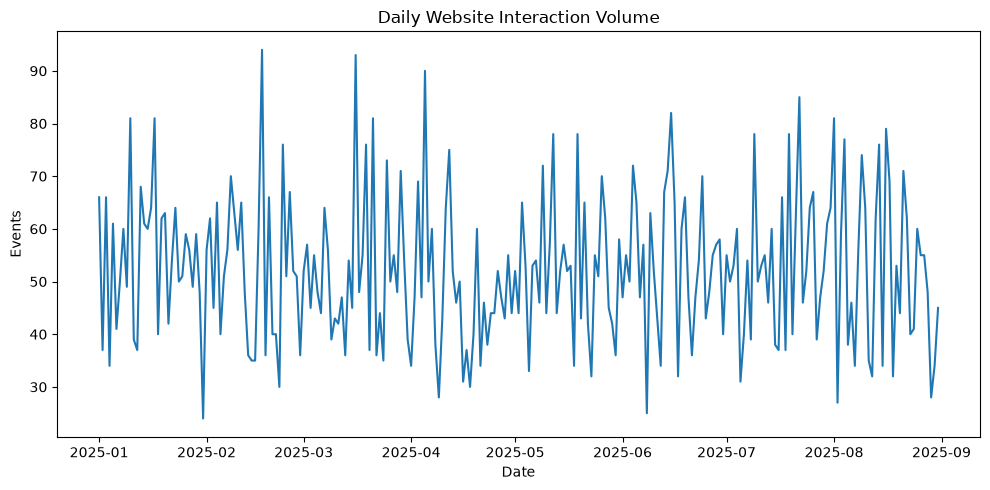

In [7]:
daily = df.set_index('Timestamp').resample('D').size()
plt.figure(figsize=(10,5)); plt.plot(daily.index,daily.values); plt.title('Daily Website Interaction Volume'); plt.xlabel('Date'); plt.ylabel('Events'); plt.tight_layout(); plt.show()

In [8]:
journeys = df.groupby('SessionID')['PageType'].agg(' → '.join).reset_index(name='Journey')
journey_counts = journeys['Journey'].value_counts().reset_index()
journey_counts.columns=['Journey','Sessions']
journey_counts.head(15)

,Journey,Sessions
0,home → product_page,2388
1,home,1013
2,home → product_page → cart → checkout → confir...,1010
3,home → product_page → cart,476
4,home → product_page → cart → checkout,113
